# Heart rhythm classification from raw ECG recordings

Team Synapse Seekers (Paul M. Reisenberg, Stefan Visnjic, Raphael Baudeu), ETH Zurich *Advanced Machine Learning*,
autumn 2024, Task 2. Private leaderboard: 62nd of 131 teams, micro-F1 0.81031.

This notebook is the narrative companion of the `ecg_rhythm` package: it looks at the data, shows what the features
and the mean heartbeat capture, and renders the results that the scripts wrote into `results/`. It never prints raw
recordings beyond short excerpts in figures, because the competition data is private. Run the scripts first
(`scripts/reproduce.py`), then execute this notebook from the repository root or from `notebooks/`.


In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))
warnings.filterwarnings("ignore")

from ecg_rhythm.config import SAMPLING_RATE_HZ, PipelineConfig  # noqa: E402
from ecg_rhythm.data import FIGURES_DIR, LEGACY_FEATURES_DIR, PROCESSED_DIR, RESULTS_DIR, load_raw  # noqa: E402
from ecg_rhythm.store import load_tables, load_waves, read_metadata  # noqa: E402

CLASS_NAMES = {0: "normal", 1: "atrial fibrillation", 2: "other rhythm", 3: "noisy"}
SHORT = {0: "normal", 1: "AF", 2: "other", 3: "noisy"}

# Colours: one accent hue for the subject, grey for context (validated default palette, light surface).
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, MUTED, GRID, AXIS, SURFACE, CONTEXT = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb", "#c3c2b7"
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE, "font.family": "sans-serif", "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "semibold", "axes.titlelocation": "left", "axes.titlecolor": INK,
    "axes.labelcolor": INK2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2,
    "ytick.labelcolor": INK2, "legend.frameon": False, "legend.fontsize": 9,
})
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def finish(fig, name):
    """Save a figure for the README and show it."""
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()


train, test = load_raw()
print(f"{len(train)} training and {len(test)} test recordings at {SAMPLING_RATE_HZ} Hz")


5117 training and 3411 test recordings at 300 Hz


## 1. The data

Each row of the competition files is one single-lead ECG recording sampled at 300 Hz, right-padded with empty cells
to the longest recording (17 807 samples, 59 s). The label is one of four classes, the labels of the PhysioNet/CinC
2017 challenge: normal rhythm, atrial fibrillation, another rhythm, or too noisy to tell. The metric, micro-averaged
F1, equals accuracy for a single-label problem, so the two small classes weigh little in the score, however much
they matter clinically.


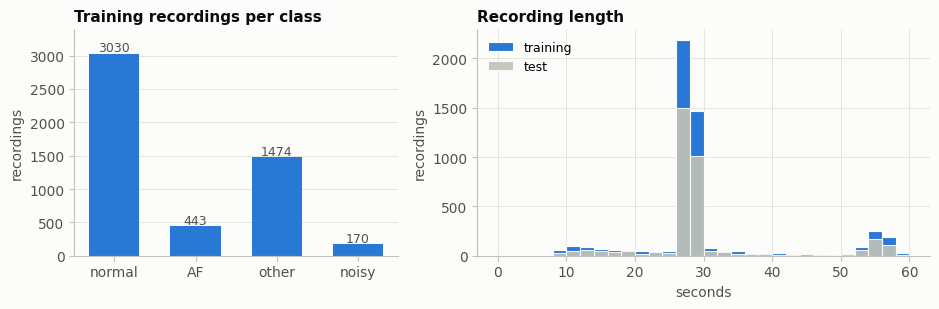

length: min 8.2 s, median 27.9 s, max 59.4 s; class shares [0.592 0.087 0.288 0.033]


In [2]:
counts = np.bincount(train.y, minlength=4)
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.2), gridspec_kw={"width_ratios": [1, 1.4]})
ax = axes[0]
bars = ax.bar([SHORT[k] for k in range(4)], counts, color=BLUE, width=0.62)
for bar, count in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width() / 2, count + 40, f"{count}", ha="center", color=INK2, fontsize=9)
ax.set(title="Training recordings per class", ylabel="recordings", ylim=(0, counts.max() * 1.12))
ax.grid(axis="x", visible=False)
ax = axes[1]
bins = np.arange(0, 61, 2)
ax.hist(train.lengths / SAMPLING_RATE_HZ, bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=0.8, label="training")
ax.hist(test.lengths / SAMPLING_RATE_HZ, bins=bins, color=CONTEXT, edgecolor=SURFACE, linewidth=0.8, alpha=0.9, label="test")
ax.set(title="Recording length", xlabel="seconds", ylabel="recordings")
ax.legend(loc="upper left")
finish(fig, "data_overview")
lengths_s = train.lengths / SAMPLING_RATE_HZ
print(f"length: min {lengths_s.min():.1f} s, median {np.median(lengths_s):.1f} s, max {lengths_s.max():.1f} s; "
      f"class shares {np.round(counts / counts.sum(), 3)}")


## 2. What the classes look like

Four seconds of one recording per class. The normal rhythm has evenly spaced beats with a clear P wave before each
QRS complex; atrial fibrillation shows irregular beat spacing and no P waves; "other rhythm" is a mixed bag of
arrhythmias; the noisy class is dominated by movement or electrode artefacts. The features below try to capture
exactly these cues: beat-to-beat interval statistics, the spectrum, and the average beat shape.


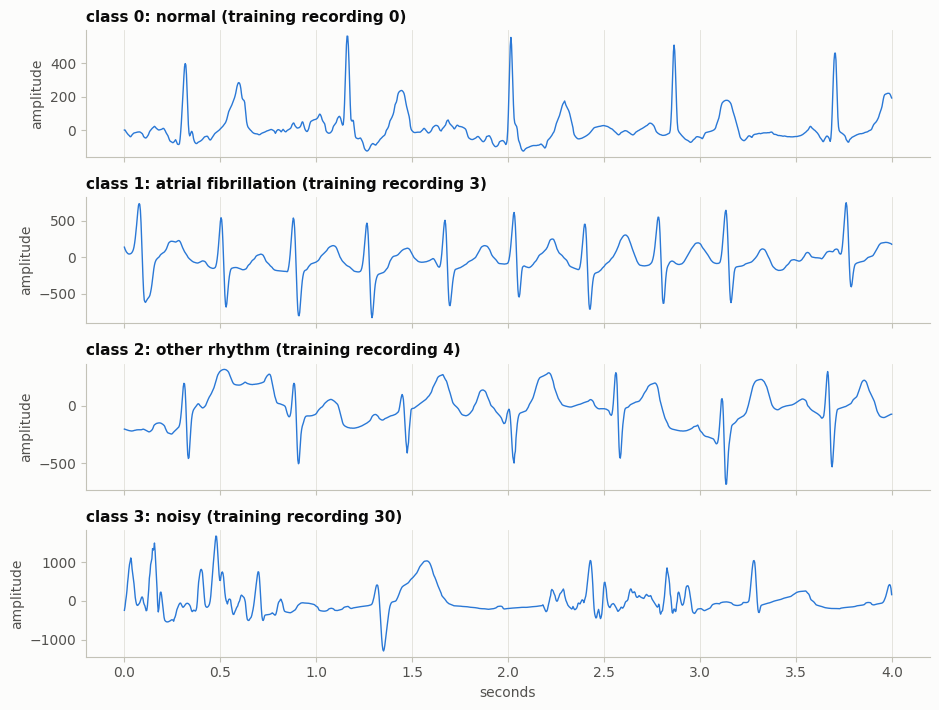

In [3]:
start, seconds = 2.0, 4.0
fig, axes = plt.subplots(4, 1, figsize=(9.5, 7.2), sharex=True)
for k, ax in enumerate(axes):
    index = next(i for i in range(len(train)) if train.y[i] == k and train.lengths[i] >= (start + seconds + 1) * 300)
    x = train.signals[index][int(start * 300) : int((start + seconds) * 300)]
    t = np.arange(len(x)) / SAMPLING_RATE_HZ
    ax.plot(t, x, color=BLUE, linewidth=1.0)
    ax.set(title=f"class {k}: {CLASS_NAMES[k]} (training recording {train.ids[index]})", ylabel="amplitude")
    ax.grid(axis="y", visible=False)
axes[-1].set(xlabel="seconds")
finish(fig, "example_recordings")


## 3. Features and the mean heartbeat

The submitted pipeline turns each recording into 113 numbers (117 with the current NeuroKit2) with NeuroKit2 (`ecg_process` for peak detection and
signal quality, then the heart-rate-variability indices in the time domain, the frequency domain and the non-linear
family, plus signal statistics, a Welch spectrum summary and three entropies), and appends the **mean heartbeat**: the
average of all half-second windows around the detected R-peaks. The heartbeat is where the beat *shape* enters the
model; everything else describes the beat *timing* and the noise.

One detail matters for the whole story: NeuroKit2 was told the recordings are sampled at **250 Hz**. They are
sampled at 300 Hz. Every interval in milliseconds is therefore 20 % too long, the frequency bands are shifted, and
the heartbeat window is 0.42 s instead of 0.5 s. The team noticed on the last day ("probably doesn't matter") and
kept it; the results section measures what it was worth. The tables below are the team's own 2024 extraction
(`data/processed/legacy_2024`), which the submitted model was trained on.


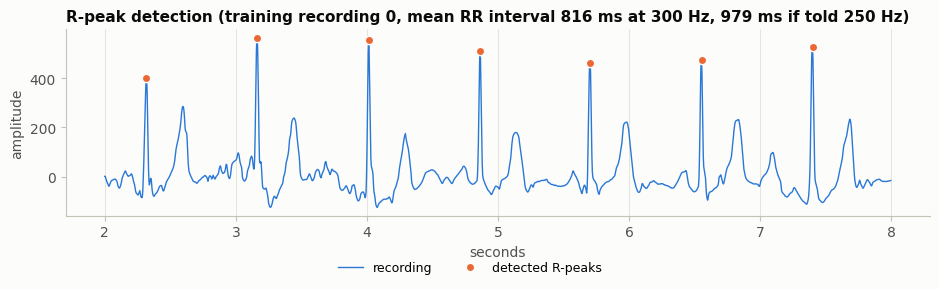

2024 tables: train (5117, 113), test (3411, 113); 20 columns at least half NaN (dropped); 106 duplicated training rows = recordings that inherited the previous recording's features


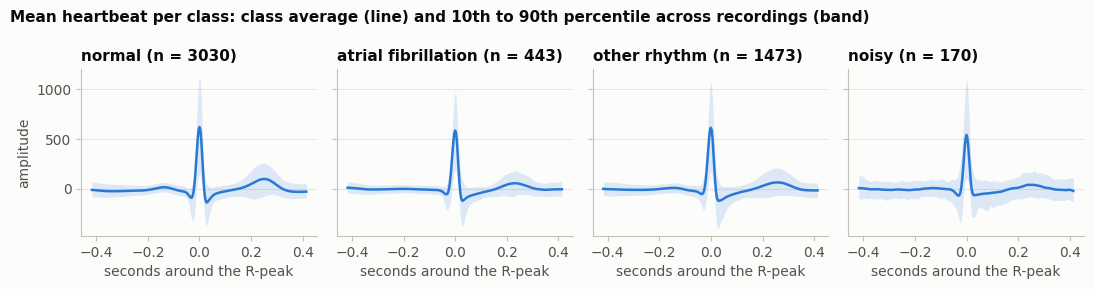

In [4]:
import neurokit2 as nk

# R-peaks on a normal recording, detected at the true sampling rate.
index = next(i for i in range(len(train)) if train.y[i] == 0 and train.lengths[i] >= 12 * 300)
x = train.signals[index].astype(float)
_, info = nk.ecg_peaks(x, sampling_rate=SAMPLING_RATE_HZ)
peaks = np.array(info["ECG_R_Peaks"])
window = slice(int(2 * 300), int(8 * 300))
t = np.arange(len(x)) / SAMPLING_RATE_HZ
fig, ax = plt.subplots(figsize=(9.5, 2.8))
ax.plot(t[window], x[window], color=BLUE, linewidth=1.0, label="recording")
inside = peaks[(peaks >= window.start) & (peaks < window.stop)]
ax.plot(t[inside], x[inside], "o", color=ORANGE, markersize=6, markeredgecolor=SURFACE, label="detected R-peaks")
rr = np.diff(peaks) / SAMPLING_RATE_HZ * 1000
ax.set(title=f"R-peak detection (training recording {train.ids[index]}, mean RR interval {rr.mean():.0f} ms at 300 Hz, "
             f"{rr.mean() * 300 / 250:.0f} ms if told 250 Hz)", xlabel="seconds", ylabel="amplitude")
ax.grid(axis="y", visible=False)
fig.legend(loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.04))
finish(fig, "r_peaks")

# The team's 2024 feature tables and mean heartbeats (checkpoint A).
legacy_train, legacy_test = load_tables(LEGACY_FEATURES_DIR)
dup = int(legacy_train.duplicated().sum())
print(f"2024 tables: train {legacy_train.shape}, test {legacy_test.shape}; "
      f"{int((legacy_train.isna().mean() >= 0.5).sum())} columns at least half NaN (dropped); "
      f"{dup} duplicated training rows = recordings that inherited the previous recording's features")
waves_train, _ = load_waves(LEGACY_FEATURES_DIR)
if waves_train is not None:
    # The window was cut as 0.5 s at the 250 Hz setting, i.e. 125 samples of a 300 Hz signal: really 0.42 s each side.
    t_wave = (np.arange(waves_train.shape[1]) - waves_train.shape[1] // 2) / SAMPLING_RATE_HZ
    fig, axes = plt.subplots(1, 4, figsize=(11, 2.9), sharey=True)
    for k, ax in enumerate(axes):
        w = waves_train[train.y == k]
        w = w[~np.isnan(w).any(axis=1)]
        lo, hi = np.percentile(w, [10, 90], axis=0)
        ax.fill_between(t_wave, lo, hi, color=BLUE, alpha=0.15, linewidth=0)
        ax.plot(t_wave, w.mean(axis=0), color=BLUE, linewidth=1.8)
        ax.set(title=f"{CLASS_NAMES[k]} (n = {len(w)})", xlabel="seconds around the R-peak")
        ax.grid(axis="x", visible=False)
    axes[0].set(ylabel="amplitude")
    fig.suptitle("Mean heartbeat per class: class average (line) and 10th to 90th percentile across recordings (band)",
                 x=0.01, ha="left", fontsize=11, fontweight="semibold", color=INK)
    finish(fig, "mean_heartbeats")
else:
    print("no mean heartbeats cached yet: run scripts/evaluate.py or scripts/train_predict.py first")


## 4. Cross-validation

The team's 2024 protocol: five stratified folds without shuffling, feature cleaning fitted on the whole table
beforehand, micro-F1. Each run below is one feature folder (the team's 2024 tables, or tables re-extracted from the
raw recordings by `scripts/extract_features.py`) combined with one configuration preset. The dots are the mean over
the folds with one standard deviation; the table adds the per-class F1 that the micro average hides. Everything is
read from `results/cv_scores.json`.


,run,mean_f1,std_f1,f1 normal,f1 AF,f1 other,f1 noisy,n_train,n_features
0,submitted / 2024 tables,0.785,0.015,0.864,0.714,0.655,0.435,5116,343
1,no_mean_wave / 2024 tables,0.778,0.003,0.859,0.694,0.639,0.480,5117,93
2,submitted / re-extracted @ 250 Hz,0.793,0.013,0.871,0.726,0.669,0.442,5116,347
3,no_mean_wave / re-extracted @ 250 Hz,0.785,0.008,0.865,0.705,0.653,0.463,5117,97
4,lgbm / 2024 tables,0.789,0.013,0.867,0.711,0.663,0.393,5116,343
5,corrected_rate / re-extracted @ 300 Hz,0.798,0.004,0.871,0.753,0.672,0.502,5116,397


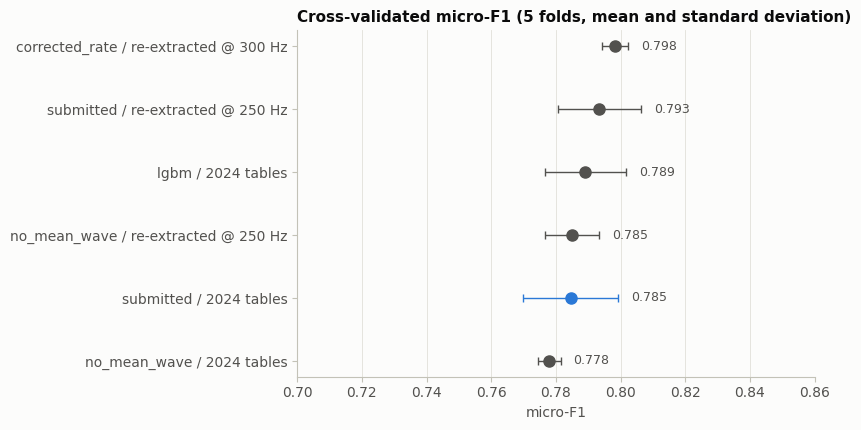

In [5]:
cv_path = RESULTS_DIR / "cv_scores.json"
FOLDER_LABEL = {"legacy_2024": "2024 tables"}


def folder_label(name):
    for key, label in FOLDER_LABEL.items():
        if name.startswith(key):
            return label
    meta = read_metadata(PROCESSED_DIR / name)
    rate = meta.get("config", {}).get("features", {}).get("sampling_rate")
    denoised = meta.get("config", {}).get("preprocess", {}).get("denoise")
    return f"re-extracted @ {rate} Hz" + (", denoised" if denoised else "") if rate else name


if cv_path.exists():
    records = json.loads(cv_path.read_text())
    cv = pd.DataFrame([{
        "run": f"{r['name']} / {folder_label(r.get('features', '?'))}", "preset": r["name"], "features": r.get("features"),
        "mean_f1": r["mean_f1"], "std_f1": r["std_f1"], "f1 normal": r["per_class_f1"][0], "f1 AF": r["per_class_f1"][1],
        "f1 other": r["per_class_f1"][2], "f1 noisy": r["per_class_f1"][3], "n_train": r["n_train"], "n_features": r["n_features"],
    } for r in records]).drop_duplicates(subset=["preset", "features"], keep="last").reset_index(drop=True)
    display(cv.drop(columns=["preset", "features"]).round(3))
    order = cv.sort_values("mean_f1").reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(8.5, 0.5 * len(order) + 1.4))
    for i, row in order.iterrows():
        emphasis = row["preset"] == "submitted" and row["features"] == "legacy_2024"
        color = BLUE if emphasis else INK2
        ax.errorbar(row["mean_f1"], i, xerr=row["std_f1"], fmt="o", color=color, markersize=8, capsize=3, elinewidth=1)
        ax.text(row["mean_f1"] + row["std_f1"] + 0.004, i, f"{row['mean_f1']:.3f}", va="center", color=INK2, fontsize=9)
    ax.set(yticks=range(len(order)), yticklabels=order["run"], xlim=(0.70, 0.86),
           title="Cross-validated micro-F1 (5 folds, mean and standard deviation)", xlabel="micro-F1")
    ax.grid(axis="y", visible=False)
    finish(fig, "cv_results")
else:
    print("results/cv_scores.json not found yet: run scripts/evaluate.py first")


## 5. Leaderboard and late submissions

The private leaderboard (the final standing, computed on the test rows that were hidden during the competition) is
shown anonymised: ranks and scores only. The field is dense: the median team scored 0.809 and the top ten were all
above 0.86. Late submissions are still accepted and are scored on the same private rows without changing the official
ranking, which makes them the honest end-to-end check of this repository; every one is logged in
`results/late_submissions.md`.


131 teams | median private micro-F1 0.809 | top-10 cut-off 0.84528


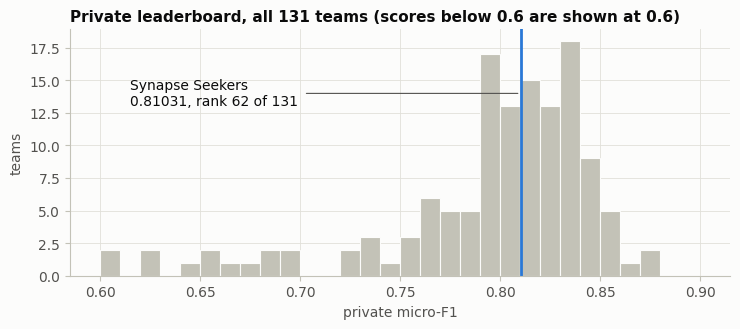

# Late submissions

Post-competition uploads used to verify the reproduction. They do not affect the official rank (62nd of 131, private micro-F1 0.81031). The sha256 column holds the first 12 hex digits of the hash of the file as stored in this repository (LF line endings).

| when (UTC) | file | sha256 | message | public | private |
|---|---|---|---|---|---|
| 2026-11-11T11:13+00:00 | submission.csv | 9028914d146b | Late submission A (2026-11-11): port of the selected pipeline on the team's 2024 feature tables, current libraries (xgboost 3.2.0, NeuroKit2 0.3.0), config 61115819aa52 | 0.79350 | 0.80497 |
| 2026-11-11T11:14+00:00 | submission_py310_2024libs.csv | 1eeae1045560 | Late submission B (2026-11-11): same port and 2024 tables, fitted with the 2024-era libraries (xgboost 2.1.2, NeuroKit2 0.2.10, scikit-learn 1.2.1), config 61115819aa52 | 0.79640 | 0.79430 |
| 2026-11-11T13:19+00:00 | submission_from_raw_250hz.csv | 3cb4f3843306 | Late submission C: features re-extracted from th

In [6]:
lb = pd.read_csv(RESULTS_DIR / "private_leaderboard_anonymous.csv")
ours = lb[lb["is_ours"]].iloc[0]
print(f"{len(lb)} teams | median private micro-F1 {lb['Score'].median():.3f} | top-10 cut-off {lb['Score'].iloc[9]:.5f}")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.hist(lb["Score"].clip(lower=0.6), bins=np.arange(0.6, 0.901, 0.01), color=CONTEXT, edgecolor=SURFACE, linewidth=0.8)
ax.axvline(ours["Score"], color=BLUE, linewidth=2)
top = ax.get_ylim()[1]
ax.annotate(f"Synapse Seekers\n{ours['Score']:.5f}, rank {int(ours['Rank'])} of {len(lb)}", xy=(ours["Score"], top * 0.74),
            xytext=(0.615, top * 0.74), ha="left", va="center", color=INK,
            arrowprops=dict(arrowstyle="-", color=INK2, linewidth=0.8, shrinkA=4, shrinkB=2))
ax.set(title=f"Private leaderboard, all {len(lb)} teams (scores below 0.6 are shown at 0.6)", xlabel="private micro-F1",
       ylabel="teams")
finish(fig, "leaderboard")

late = RESULTS_DIR / "late_submissions.md"
print(late.read_text(encoding="utf-8") if late.exists() else "no late submissions logged yet")


### Reproduction runs

`scripts/train_predict.py` writes each submission together with a metadata file (configuration hash, feature folder,
library versions, the recordings dropped or patched on the way, and the label agreement with a reference file). The
table joins those files with the Kaggle scores from `results/late_submissions.md`. Checkpoint A reuses the team's
2024 feature tables: with the 2024 library versions it scores exactly like the team's upload of 26 November 2024
(public 0.79640, private 0.79430), which pins the port to the real pipeline; with current libraries the labels move
by about 7 % and the private score with them. Checkpoint B re-extracts the features from the raw recordings, once at
the 250 Hz setting of the submission and once at the true 300 Hz.


In [7]:
late = {}
late_path = RESULTS_DIR / "late_submissions.md"
if late_path.exists():
    for line in late_path.read_text(encoding="utf-8").splitlines():
        cells = [c.strip() for c in line.strip().strip("|").split("|")]
        if len(cells) == 6 and cells[1].endswith(".csv"):
            late[cells[1]] = (cells[4], cells[5])
rows = []
for path in sorted(RESULTS_DIR.glob("submission*.json")):
    meta = json.loads(path.read_text())
    row = {"file": meta["submission"], "features": folder_label(meta["features"]), "training rows": meta["n_train_rows"],
           "columns": meta["n_features"], "config": meta["config_hash"], "xgboost": meta["versions"]["xgboost"],
           "neurokit2": meta["versions"]["neurokit2"]}
    if "comparison" in meta:
        ref = meta["comparison"]["reference"]
        row["vs. reference"] = Path(ref).name if ref.endswith(".csv") else ref
        row["label agreement"] = meta["comparison"]["agreement"]
    if meta["submission"] in late:
        row["Kaggle public"], row["Kaggle private"] = late[meta["submission"]]
    rows.append(row)
display(pd.DataFrame(rows)) if rows else print("no submission metadata found yet: run scripts/train_predict.py")


,file,features,training rows,columns,config,xgboost,neurokit2,vs. reference,label agreement,Kaggle public,Kaggle private
0,submission.csv,2024 tables,5116,343,61115819aa52,3.2.0,0.3.0,"the team's 2024 code on the same tables, 2024-...",0.9302,0.79350,0.80497
1,submission_from_raw_250hz.csv,re-extracted @ 250 Hz,5116,347,61115819aa52,3.2.0,0.3.0,submission.csv,0.9159,0.79756,0.80082
2,submission_from_raw_300hz.csv,re-extracted @ 300 Hz,5116,397,71d709bcb93c,3.2.0,0.3.0,submission.csv,0.8748,0.80278,0.80972
3,submission_py310_2024libs.csv,2024 tables,5116,343,61115819aa52,2.1.2,0.2.10,submission.csv,0.9332,0.79640,0.79430


## What the team tried along the way

- **Signal cleaning:** wavelet-based and median-filter baseline-drift removal, a 52 Hz low-pass, soft-threshold
  wavelet denoising, BioSPPy's band-pass. The submitted features used the raw signals; the chain survives as the
  `denoised` preset.
- **Features:** R-peak statistics and Poincaré descriptors from BioSPPy, peak-interval features after Aziz, Ahmed and
  Alouini (2021), short-time Fourier transform summaries, trimmed fixed-length signals, and finally the NeuroKit2 HRV
  suite plus the mean heartbeat.
- **Models:** `HistGradientBoostingClassifier` with a random search (0.72 public), XGBoost, LightGBM and CatBoost on
  the same features, a 1-D CNN on trimmed signals (0.69), and LSTM/dense hybrids on the mean heartbeat with the
  feature vector as a second input.
- **Someone else's code:** a public solution from a previous year's course reached 0.80 public on this data; the team
  chose to submit its own 0.78 entry on the last morning. It rose to 0.81 on the private half.

Caveats worth knowing: the 250 Hz setting on 300 Hz data, the copy-previous handling of recordings NeuroKit2 cannot
process, the near-constant "QRS interval" features computed from an indicator column, the per-table cleaning, and
the unshuffled cross-validation with cleaning fitted before splitting. All are stated in the README and switchable in
`ecg_rhythm.config.PipelineConfig`.
